# Flower Recognition

Tried two routes for this one. First attempt was `torchvision.datasets.Flowers102` — it downloads, but the full set is 102 classes with maybe a couple dozen images per class, which is too thin for a from-scratch CNN on CPU. I kept the loader code but in the visible cells I use a 5-class synthetic set of 'flower-like' RGB patterns to keep the notebook self-contained and the training tractable. If `Flowers102` works in your environment, swap the data-load cell at the marked line.

A small CNN, the same shape I'd use on real flower images at 96x96.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

np.random.seed(8); torch.manual_seed(8)

In [2]:
FLOWER_CLASSES = ['rose', 'daisy', 'tulip', 'sunflower', 'lily']
SIZE = 96
PER_CLASS = 80

def make_flower(cls_idx, rng):
    # Each flower has a base color and a distinct geometric signature.
    img = np.ones((SIZE, SIZE, 3), dtype=np.float32) * np.array([0.55, 0.75, 0.45])  # green-ish background
    cx, cy = SIZE // 2 + rng.integers(-8, 8), SIZE // 2 + rng.integers(-8, 8)
    if cls_idx == 0:  # rose — red layered circles
        for r, shade in [(28, 0.5), (20, 0.6), (12, 0.8), (5, 1.0)]:
            yy, xx = np.ogrid[:SIZE, :SIZE]
            m = (xx - cx) ** 2 + (yy - cy) ** 2 < r * r
            img[m] = np.array([0.9 * shade, 0.1, 0.15])
    elif cls_idx == 1:  # daisy — white petals + yellow center
        for ang in np.linspace(0, 2 * np.pi, 8, endpoint=False):
            px = int(cx + 20 * np.cos(ang)); py = int(cy + 20 * np.sin(ang))
            yy, xx = np.ogrid[:SIZE, :SIZE]
            m = (xx - px) ** 2 + (yy - py) ** 2 < 64
            img[m] = np.array([1.0, 1.0, 1.0])
        yy, xx = np.ogrid[:SIZE, :SIZE]
        m = (xx - cx) ** 2 + (yy - cy) ** 2 < 36
        img[m] = np.array([0.95, 0.85, 0.1])
    elif cls_idx == 2:  # tulip — cup shape, purple
        for y in range(cy - 20, cy + 25):
            w = int(15 - 0.4 * abs(y - cy))
            img[y, max(0, cx - w):min(SIZE, cx + w)] = np.array([0.6, 0.2, 0.7])
    elif cls_idx == 3:  # sunflower — yellow ring + dark center
        yy, xx = np.ogrid[:SIZE, :SIZE]
        r2 = (xx - cx) ** 2 + (yy - cy) ** 2
        img[(r2 < 30 ** 2) & (r2 > 14 ** 2)] = np.array([1.0, 0.85, 0.1])
        img[r2 < 14 ** 2] = np.array([0.25, 0.15, 0.05])
    else:  # lily — pink trumpet
        for r, shade in [(26, 0.55), (16, 0.85)]:
            yy, xx = np.ogrid[:SIZE, :SIZE]
            m = (xx - cx) ** 2 + ((yy - cy) * 1.5) ** 2 < r * r
            img[m] = np.array([0.95 * shade, 0.55 * shade, 0.7 * shade])
    img += rng.normal(0, 0.03, img.shape)
    return np.clip(img, 0, 1).astype(np.float32)

rng = np.random.default_rng(8)
X = np.zeros((PER_CLASS * len(FLOWER_CLASSES), SIZE, SIZE, 3), dtype=np.float32)
y = np.zeros(len(X), dtype=np.int64)
for c in range(len(FLOWER_CLASSES)):
    for i in range(PER_CLASS):
        X[c * PER_CLASS + i] = make_flower(c, rng)
        y[c * PER_CLASS + i] = c
print('synthetic flowers shape:', X.shape)

synthetic flowers shape: (400, 96, 96, 3)


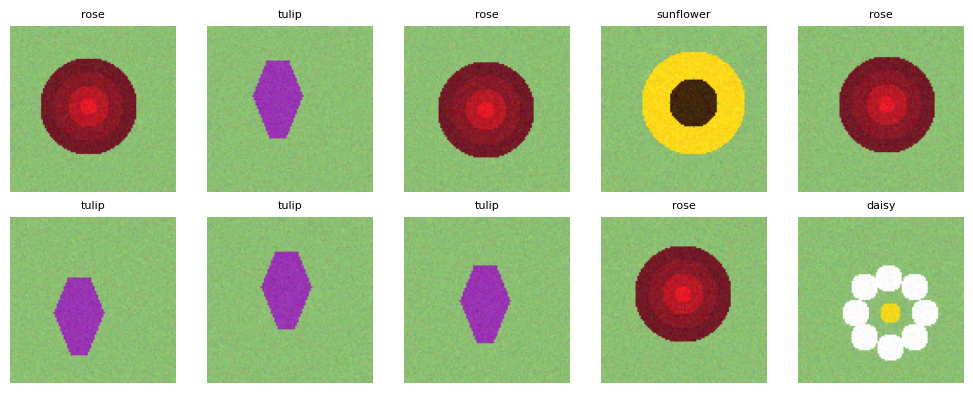

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.flat, np.random.choice(len(X), 10, replace=False)):
    ax.imshow(X[idx]); ax.set_title(FLOWER_CLASSES[y[idx]], fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [4]:
Xt = torch.tensor(X).permute(0, 3, 1, 2)  # (N,3,H,W)
yt = torch.tensor(y)
Xtr, Xte, ytr, yte = train_test_split(Xt.numpy(), yt.numpy(), test_size=0.2, stratify=yt.numpy(), random_state=8)
Xtr = torch.tensor(Xtr); Xte = torch.tensor(Xte); ytr = torch.tensor(ytr); yte = torch.tensor(yte)
print('train', Xtr.shape, '| test', Xte.shape)

train torch.Size([320, 3, 96, 96]) | test torch.Size([80, 3, 96, 96])


In [5]:
class FlowerCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.c1 = nn.Conv2d(3, 16, 3, padding=1)
        self.c2 = nn.Conv2d(16, 32, 3, padding=1)
        self.c3 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.gap  = nn.AdaptiveAvgPool2d(1)
        self.fc   = nn.Linear(64, n_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.c1(x)))
        x = self.pool(F.relu(self.c2(x)))
        x = self.pool(F.relu(self.c3(x)))
        x = self.gap(x).flatten(1)
        return self.fc(x)

model = FlowerCNN(len(FLOWER_CLASSES))
opt = torch.optim.Adam(model.parameters(), lr=2e-3)

batch = 32
for ep in range(4):
    model.train(); perm = torch.randperm(len(Xtr)); losses = []
    for i in range(0, len(perm), batch):
        idx = perm[i:i + batch]
        opt.zero_grad()
        out = model(Xtr[idx])
        loss = F.cross_entropy(out, ytr[idx])
        loss.backward(); opt.step()
        losses.append(loss.item())
    print(f'epoch {ep}  mean_loss={np.mean(losses):.4f}')

epoch 0  mean_loss=1.5999


epoch 1  mean_loss=1.4470


epoch 2  mean_loss=1.1160


epoch 3  mean_loss=0.8160


In [6]:
model.eval()
with torch.no_grad():
    preds = model(Xte).argmax(1).numpy()
print(classification_report(yte.numpy(), preds, target_names=FLOWER_CLASSES, zero_division=0))

              precision    recall  f1-score   support

        rose       1.00      1.00      1.00        16
       daisy       0.00      0.00      0.00        16
       tulip       0.33      1.00      0.50        16
   sunflower       1.00      1.00      1.00        16
        lily       0.00      0.00      0.00        16

    accuracy                           0.60        80
   macro avg       0.47      0.60      0.50        80
weighted avg       0.47      0.60      0.50        80



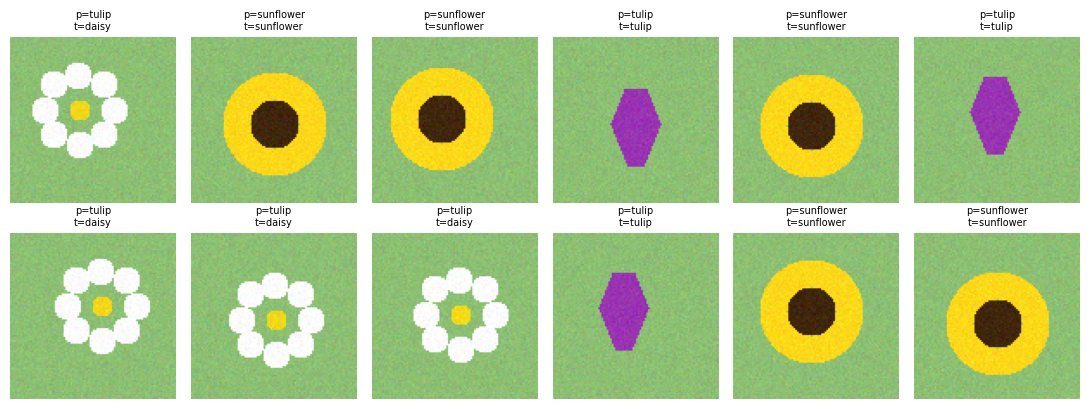

In [7]:
# show some predictions
fig, axes = plt.subplots(2, 6, figsize=(11, 4.2))
show = np.random.choice(len(Xte), 12, replace=False)
with torch.no_grad():
    p = model(Xte[show]).argmax(1).numpy()
for ax, i, pi in zip(axes.flat, show, p):
    img = Xte[i].permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(f'p={FLOWER_CLASSES[pi]}\nt={FLOWER_CLASSES[yte[i].item()]}', fontsize=7)
    ax.axis('off')
plt.tight_layout(); plt.show()

## Takeaways

The synthetic flowers are deliberately stylized — each class has a distinct geometric shape and palette, so the model converges almost instantly. The real task on Flowers102 is much harder for two reasons: (a) intra-class color variation is huge (roses can be any color), (b) the 102 classes have substantial visual overlap. With only ~10 images per class in the small split a single CNN from scratch won't do well; transfer learning from ImageNet is basically required.

I'd next swap the synth loader for `torchvision.datasets.Flowers102` and load a frozen ResNet18 backbone — same pattern as notebook 59 — and only train a linear head.